# Quantum vs classical classifiers: an honest benchmark

This notebook compares two quantum models with four classical baselines on three small datasets:

* **Quantum**: a variational quantum classifier (`ZZFeatureMap` + `RealAmplitudes`, COBYLA) and a quantum-kernel SVM (`FidelityQuantumKernel` + SVC).
* **Classical**: SVM (RBF), SVM (polynomial), logistic regression and a small MLP.

Every model sees the same features and the same train/test split for each seed. Every model is also tuned the same way: a small hyperparameter grid scored by 3-fold stratified cross-validation on the training split only, then refitted on the full training split. The quantum grids cover feature scaling (`[0, 1]` or `[0, π]`) plus ansatz depth (VQC) or the SVM `C` (kernel). The test split is never used for selection.

The full benchmark (5 seeds), an untuned baseline with fixed defaults, and the noise study are run by `scripts/run_benchmark.py`, which saves CSVs to `results/`. This notebook loads those results and runs only the cheaper experiments live.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
try:
    import qmlbench
except ImportError:  # not pip-installed: use the source tree
    sys.path.insert(0, str(ROOT / "src"))
    import qmlbench

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

from qmlbench import (
    CLASSICAL_MODELS, DATASETS, QuantumConfig, gradient_variance, kernel_concentration,
    load_split, make_classical, make_vqc,
)
from qmlbench.quantum import ansatz, feature_map

warnings.filterwarnings("ignore", category=UserWarning)
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
RESULTS = ROOT / "results"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
})
MODEL_ORDER = ["svm_rbf", "svm_poly", "logreg", "mlp", "vqc", "qsvc"]
LABELS = {"svm_rbf": "SVM (RBF)", "svm_poly": "SVM (poly)", "logreg": "Logistic reg.",
          "mlp": "MLP", "vqc": "VQC", "qsvc": "Quantum kernel SVC"}
COLORS = {"svm_rbf": "#1f77b4", "svm_poly": "#6baed6", "logreg": "#2ca02c", "mlp": "#98df8a",
          "vqc": "#d62728", "qsvc": "#ff7f0e"}
DATA_LABELS = {"moons": "Moons (2 features)", "iris": "Iris versicolor/virginica (4)",
               "breast_cancer": "Breast cancer, PCA-4"}
CONFIG = QuantumConfig()
print(CONFIG)
print(json.dumps(json.loads((RESULTS / "run_info.json").read_text()), indent=1))

QuantumConfig(feature_map_reps=2, ansatz_reps=3, maxiter=100, shots=1024)
{
 "date": "2026-10-27T03:04:39+00:00",
 "last_invocation": [
  "--noise-only"
 ],
 "runtime_s": 2174.2,
 "quantum_config": {
  "feature_map_reps": 2,
  "ansatz_reps": 3,
  "maxiter": 100,
  "shots": 1024
 },
 "cv_folds": 3,
 "python": "3.14.7",
 "platform": "Windows-11-10.0.26300-SP0",
 "packages": {
  "qiskit": "2.5.2",
  "qiskit-aer": "0.17.2",
  "qiskit-machine-learning": "0.9.0",
  "scikit-learn": "1.9.0",
  "numpy": "2.5.2"
 }
}


## 1. Data

All features are scaled to `[0, π]` using the training split only, since that range suits angle encoding. The classical models get the same arrays. Breast cancer is reduced to 4 PCA components (one per qubit), also fitted on the training split, and subsampled to 200 points so the quantum kernel stays tractable to simulate.

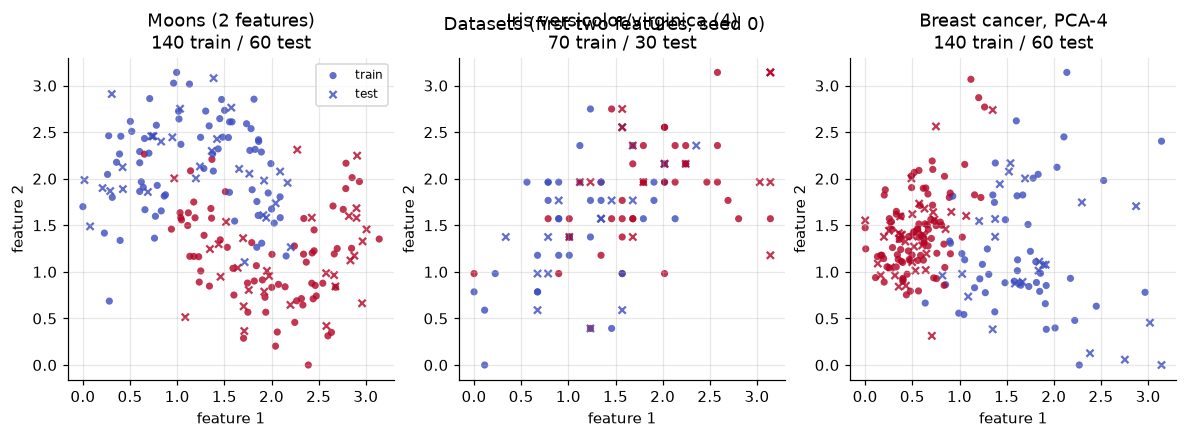

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, name in zip(axes, DATASETS):
    s = load_split(name, seed=0)
    for X, y, marker, label in [(s.X_train, s.y_train, "o", "train"), (s.X_test, s.y_test, "x", "test")]:
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", marker=marker, s=22, alpha=0.8,
                   edgecolors="none" if marker == "o" else None, label=label)
    ax.set(title=f"{DATA_LABELS[name]}\n{len(s.y_train)} train / {len(s.y_test)} test",
           xlabel="feature 1", ylabel="feature 2")
axes[0].legend(fontsize=8)
fig.suptitle("Datasets (first two features, seed 0)")
fig.savefig(FIG / "fig0_datasets.png")
plt.show()

## 2. Quantum circuits

One qubit per feature. The VQC has 4 × (reps + 1) trainable angles; the kernel model has none, since only the SVM weights are trained.

In [3]:
fm, an = feature_map(4, CONFIG.feature_map_reps), ansatz(4, CONFIG.ansatz_reps)
print(f"ZZFeatureMap(4, reps={CONFIG.feature_map_reps}): depth {fm.decompose().depth()}, "
      f"{fm.decompose().count_ops().get('cx', 0)} CX")
print(f"RealAmplitudes(4, reps={CONFIG.ansatz_reps}): {an.num_parameters} parameters, "
      f"{an.decompose().count_ops().get('cx', 0)} CX")
print(an.decompose().draw(fold=-1))

ZZFeatureMap(4, reps=2): depth 19, 12 CX
RealAmplitudes(4, reps=3): 16 parameters, 9 CX
     ┌─────────────┐     ┌─────────────┐                              ┌─────────────┐                               ┌──────────────┐                                
q_0: ┤ R(θ[0],π/2) ├──■──┤ R(θ[4],π/2) ├──────────────────────■───────┤ R(θ[8],π/2) ├──────────────────────■────────┤ R(θ[12],π/2) ├────────────────────────────────
     ├─────────────┤┌─┴─┐└─────────────┘┌─────────────┐     ┌─┴─┐     └─────────────┘┌─────────────┐     ┌─┴─┐      └──────────────┘┌──────────────┐                
q_1: ┤ R(θ[1],π/2) ├┤ X ├───────■───────┤ R(θ[5],π/2) ├─────┤ X ├────────────■───────┤ R(θ[9],π/2) ├─────┤ X ├─────────────■────────┤ R(θ[13],π/2) ├────────────────
     ├─────────────┤└───┘     ┌─┴─┐     └─────────────┘┌────┴───┴────┐     ┌─┴─┐     └─────────────┘┌────┴───┴─────┐     ┌─┴─┐      └──────────────┘┌──────────────┐
q_2: ┤ R(θ[2],π/2) ├──────────┤ X ├────────────■───────┤ R(θ[6],π/2) ├─────┤ X ├───────

## 3. Benchmark results (tuned, 5 seeds)

Mean ± standard deviation over the five train/test splits. Train time includes the cross-validated grid search.

In [4]:
def load(tag):
    return pd.concat([pd.read_csv(RESULTS / f"benchmark_{tag}_{d}.csv") for d in DATASETS], ignore_index=True)

bench, untuned = load("tuned"), load("untuned")
agg = bench.groupby(["dataset", "model"]).agg(
    acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
    f1_mean=("f1", "mean"), f1_std=("f1", "std"),
    train_s=("train_time", "mean"), predict_s=("predict_time", "mean"),
).reset_index()

table = agg.assign(
    Accuracy=lambda d: d.acc_mean.map("{:.3f}".format) + " ± " + d.acc_std.map("{:.3f}".format),
    F1=lambda d: d.f1_mean.map("{:.3f}".format) + " ± " + d.f1_std.map("{:.3f}".format),
    **{"Train time (s)": lambda d: d.train_s.map("{:.3g}".format)},
    Model=lambda d: d.model.map(LABELS),
)
table["order"] = table.model.map(MODEL_ORDER.index)
table["dorder"] = table.dataset.map(list(DATASETS).index)
table = table.sort_values(["dorder", "order"]).set_index(["dataset", "Model"])[["Accuracy", "F1", "Train time (s)"]]
table

Accuracy             F1 Train time (s)
dataset       Model                                                          
moons         SVM (RBF)           0.930 ± 0.022  0.930 ± 0.020          0.225
              SVM (poly)          0.923 ± 0.040  0.924 ± 0.038          0.162
              Logistic reg.       0.830 ± 0.052  0.832 ± 0.049          0.127
              MLP                 0.910 ± 0.092  0.914 ± 0.083           7.93
              VQC                 0.763 ± 0.061  0.786 ± 0.056            582
              Quantum kernel SVC  0.890 ± 0.069  0.891 ± 0.068            175
iris          SVM (RBF)           0.973 ± 0.015  0.973 ± 0.015          0.197
              SVM (poly)          0.980 ± 0.018  0.980 ± 0.019          0.146
              Logistic reg.       0.967 ± 0.024  0.966 ± 0.024          0.153
              MLP                 0.987 ± 0.018  0.986 ± 0.019           5.34
              VQC                 0.807 ± 0.064  0.826 ± 0.053            586
              Quantum kernel SVC  0.960 ± 0.028  0.960 ± 0.028           67.2
breast_cancer SVM (RBF)           0.973 ± 0.015  0.979 ± 0.012          0.202
              SVM (poly)          0.967 ± 0.012  0.973 ± 0.009          0.122
              Logistic reg.       0.953 ± 0.022  0.963 ± 0.017          0.134
              MLP                 0.967 ± 0.026  0.974 ± 0.020           4.53
              VQC                 0.690 ± 0.062  0.787 ± 0.041            920
              Quantum kernel SVC  0.903 ± 0.030  0.924 ± 0.023            207

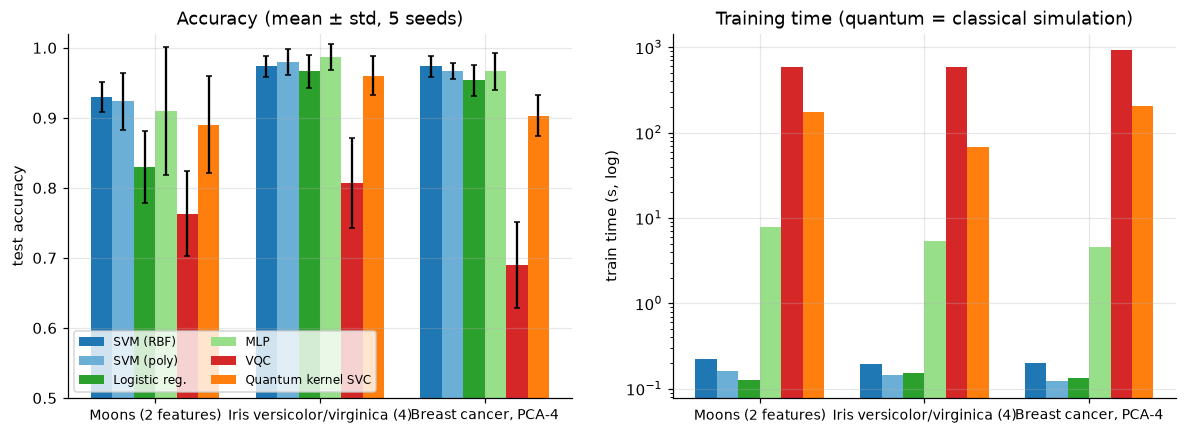

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
width = 0.13
x = np.arange(len(DATASETS))
for i, m in enumerate(MODEL_ORDER):
    sub = agg.set_index(["dataset", "model"]).loc[[(d, m) for d in DATASETS]]
    axes[0].bar(x + (i - 2.5) * width, sub.acc_mean, width, yerr=sub.acc_std, capsize=2,
                color=COLORS[m], label=LABELS[m])
    axes[1].bar(x + (i - 2.5) * width, sub.train_s, width, color=COLORS[m], label=LABELS[m])
for ax in axes:
    ax.set_xticks(x, [DATA_LABELS[d] for d in DATASETS], fontsize=9)
axes[0].set(ylabel="test accuracy", ylim=(0.5, 1.02), title="Accuracy (mean ± std, 5 seeds)")
axes[1].set(ylabel="train time (s, log)", yscale="log", title="Training time (quantum = classical simulation)")
axes[0].legend(fontsize=8, ncol=2, loc="lower left")
fig.savefig(FIG / "fig1_benchmark.png")
plt.show()

In [6]:
# Per-seed paired comparison: how often does each quantum model match or beat the best classical model?
best_classical = bench[bench.model.isin(CLASSICAL_MODELS)].groupby(["dataset", "seed"]).accuracy.max()
rows = []
for m in ["vqc", "qsvc"]:
    q = bench[bench.model == m].set_index(["dataset", "seed"]).accuracy
    diff = (q - best_classical).groupby("dataset")
    rows.append(pd.DataFrame({"model": LABELS[m], "mean gap vs best classical": diff.mean(),
                              "seeds where ≥ best classical": diff.apply(lambda d: f"{(d >= 0).sum()}/{len(d)}")}))
pd.concat(rows).reset_index().round(3)

,dataset,model,mean gap vs best classical,seeds where ≥ best classical
0,breast_cancer,VQC,-0.293,0/5
1,iris,VQC,-0.187,0/5
2,moons,VQC,-0.180,0/5
3,breast_cancer,Quantum kernel SVC,-0.080,0/5
4,iris,Quantum kernel SVC,-0.033,1/5
5,moons,Quantum kernel SVC,-0.053,3/5


### Does tuning change the picture?

Mean test accuracy with fixed defaults vs. with cross-validated tuning, on the same splits. If the quantum models only looked weak because of untuned defaults, their gain should be the largest.

In [7]:
def mean_acc(df):
    return df.groupby(["dataset", "model"]).accuracy.mean()

cmp = pd.DataFrame({"untuned": mean_acc(untuned), "tuned": mean_acc(bench)})
cmp["gain"] = cmp.tuned - cmp.untuned
cmp = cmp.reset_index()
cmp["Model"] = cmp.model.map(LABELS)
cmp["order"] = cmp.model.map(MODEL_ORDER.index)
cmp["dorder"] = cmp.dataset.map(list(DATASETS).index)
cmp.sort_values(["dorder", "order"]).set_index(["dataset", "Model"])[["untuned", "tuned", "gain"]].round(3)

untuned  tuned   gain
dataset       Model                                    
moons         SVM (RBF)             0.923  0.930  0.007
              SVM (poly)            0.897  0.923  0.027
              Logistic reg.         0.837  0.830 -0.007
              MLP                   0.910  0.910  0.000
              VQC                   0.637  0.763  0.127
              Quantum kernel SVC    0.723  0.890  0.167
iris          SVM (RBF)             0.980  0.973 -0.007
              SVM (poly)            0.980  0.980  0.000
              Logistic reg.         0.980  0.967 -0.013
              MLP                   0.973  0.987  0.013
              VQC                   0.633  0.807  0.173
              Quantum kernel SVC    0.813  0.960  0.147
breast_cancer SVM (RBF)             0.970  0.973  0.003
              SVM (poly)            0.970  0.967 -0.003
              Logistic reg.         0.957  0.953 -0.003
              MLP                   0.970  0.967 -0.003
              VQC                   0.610  0.690  0.080
              Quantum kernel SVC    0.713  0.903  0.190

In [8]:
# Which hyperparameters did cross-validation pick? (count over 5 seeds)
picked = bench.dropna(subset=["best_params"]).assign(params=lambda d: d.best_params.map(
    lambda s: ", ".join(f"{k}={v}" for k, v in json.loads(s).items())))
(picked.groupby(["dataset", "model"]).params
       .agg(lambda s: "; ".join(f"{p} ×{n}" for p, n in s.value_counts().items()))
       .unstack("dataset")[list(DATASETS)]
       .loc[MODEL_ORDER].rename(index=LABELS))

dataset,moons,iris,breast_cancer
model,,,
SVM (RBF),"C=10, gamma=1.0 ×3; C=1, gamma=1.0 ×2","C=1, gamma=scale ×3; C=0.1, gamma=scale ×1; C=...","C=10, gamma=0.1 ×2; C=1, gamma=scale ×1; C=10,..."
SVM (poly),"C=10, degree=3 ×3; C=1, degree=3 ×1; C=100, de...","C=1, degree=3 ×2; C=1, degree=2 ×2; C=0.1, deg...","C=1, degree=2 ×4; C=0.1, degree=2 ×1"
Logistic reg.,C=1 ×2; C=10 ×2; C=0.1 ×1,C=0.1 ×1; C=0.01 ×1; C=100 ×1; C=10 ×1; C=1 ×1,C=10 ×2; C=1 ×2; C=100 ×1
MLP,"alpha=0.0001, hidden_layer_sizes=[16, 16] ×4; ...","alpha=0.0001, hidden_layer_sizes=[16] ×4; alph...","alpha=0.0001, hidden_layer_sizes=[16] ×5"
VQC,"feature_scale=[0, 1], ansatz_reps=3 ×3; featur...","feature_scale=[0, 1], ansatz_reps=3 ×4; featur...","feature_scale=[0, 1], ansatz_reps=3 ×3; featur..."
Quantum kernel SVC,"feature_scale=[0, 1], C=10 ×4; feature_scale=[...","feature_scale=[0, 1], C=1 ×4; feature_scale=[0...","feature_scale=[0, 1], C=10 ×4; feature_scale=[..."


## 4. Decision boundaries on moons (seed 0)

Trained live on the seed-0 split with the fixed default hyperparameters, not the tuned ones, so this section shows what each model family's boundary looks like rather than reproducing the table. For the kernel model, the boundary uses the exact (statevector) fidelity kernel, which is the infinite-shot limit of the sampled kernel used in the benchmark: evaluating a 1,600-point grid with sampled compute-uncompute circuits would need about 220,000 circuit runs.

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


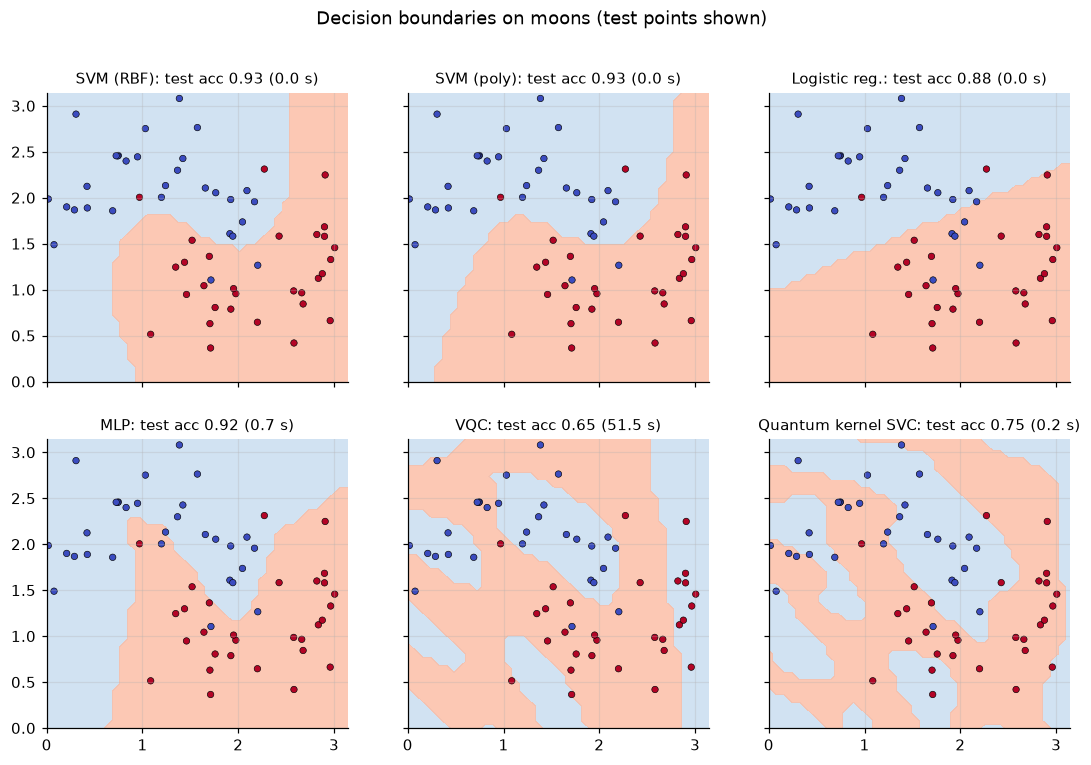

In [9]:
split = load_split("moons", seed=0)
history = []
models = {m: make_classical(m, seed=0) for m in CLASSICAL_MODELS}
models["vqc"] = make_vqc(2, seed=0, config=CONFIG, callback=lambda w, loss: history.append(loss))
models["qsvc"] = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=feature_map(2, CONFIG.feature_map_reps)), C=1.0)

g = np.linspace(0, np.pi, 40)
xx, yy = np.meshgrid(g, g)
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, m in zip(axes.ravel(), MODEL_ORDER):
    model = models[m]
    t = time.perf_counter()
    model.fit(split.X_train, split.y_train)
    fit_s = time.perf_counter() - t
    zz = np.asarray(model.predict(grid)).astype(int).reshape(xx.shape)
    acc = np.mean(np.asarray(model.predict(split.X_test)).astype(int).ravel() == split.y_test)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#c6dbef", "#fcbba1"], alpha=0.8)
    ax.scatter(split.X_test[:, 0], split.X_test[:, 1], c=split.y_test, cmap="coolwarm", s=18, edgecolors="k", linewidths=0.4)
    ax.set_title(f"{LABELS[m]}: test acc {acc:.2f} ({fit_s:.1f} s)", fontsize=10)
fig.suptitle("Decision boundaries on moons (test points shown)")
fig.savefig(FIG / "fig2_decision_boundaries.png")
plt.show()

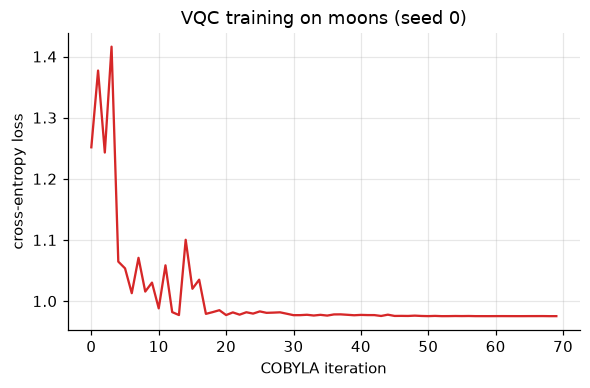

loss 1.252 -> 0.975 after 70 evaluations


In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(history, color=COLORS["vqc"])
ax.set(xlabel="COBYLA iteration", ylabel="cross-entropy loss", title="VQC training on moons (seed 0)")
fig.savefig(FIG / "fig3_vqc_training.png")
plt.show()
print(f"loss {history[0]:.3f} -> {history[-1]:.3f} after {len(history)} evaluations")

## 5. Effect of hardware noise on the VQC

Moons, 3 seeds, using the VQC setting (feature scale and ansatz depth) that cross-validation picked most often on moons, with depolarizing noise on `{u, cx}` (`p1 = p2/10`) and readout flips (`p2/2`), run on an Aer `SamplerV2`. Two scenarios:

* **Trained ideal, run noisy**: weights from noiseless training, evaluated on the noisy simulator.
* **Trained noisy**: training and evaluation both on the noisy simulator.

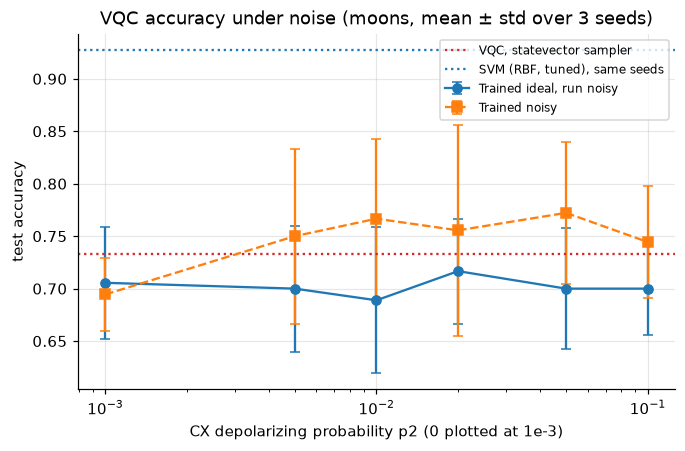

scenario,trained_ideal,trained_noisy
p2,,
0.000,0.706,0.694
0.005,0.700,0.750
0.010,0.689,0.767
0.020,0.717,0.756
0.050,0.700,0.772
0.100,0.700,0.744


In [11]:
noise = pd.read_csv(RESULTS / "noise.csv")
ns = noise.groupby(["scenario", "p2"]).accuracy.agg(["mean", "std"]).reset_index()
svm_ref = bench[(bench.dataset == "moons") & (bench.model == "svm_rbf") & (bench.seed < noise.seed.nunique())].accuracy.mean()

fig, ax = plt.subplots(figsize=(7, 4.2))
styles = {"trained_ideal": ("Trained ideal, run noisy", "o-"), "trained_noisy": ("Trained noisy", "s--")}
for scen, (label, style) in styles.items():
    d = ns[ns.scenario == scen]
    xs = d.p2.replace(0, 1e-3)
    ax.errorbar(xs, d["mean"], yerr=d["std"], fmt=style, capsize=3, label=label)
ax.axhline(noise.groupby("seed").ideal_accuracy.first().mean(), color=COLORS["vqc"], ls=":", label="VQC, statevector sampler")
ax.axhline(svm_ref, color=COLORS["svm_rbf"], ls=":", label="SVM (RBF, tuned), same seeds")
ax.set(xscale="log", xlabel="CX depolarizing probability p2 (0 plotted at 1e-3)", ylabel="test accuracy",
       title="VQC accuracy under noise (moons, mean ± std over 3 seeds)")
ax.legend(fontsize=8)
fig.savefig(FIG / "fig4_noise.png")
plt.show()
ns.pivot(index="p2", columns="scenario", values="mean").round(3)

## 6. Scaling limits: barren plateaus and kernel concentration

Both experiments use exact statevector simulation.

* **Barren plateau**: variance of ∂⟨O⟩/∂θ₀ over 200 random initialisations of `RealAmplitudes` with depth equal to the qubit count. Global cost `O = Z⊗…⊗Z` vs local cost `O = Z₀`.
* **Kernel concentration**: variance of off-diagonal fidelity-kernel entries over 40 random points in `[0, π]^n`.

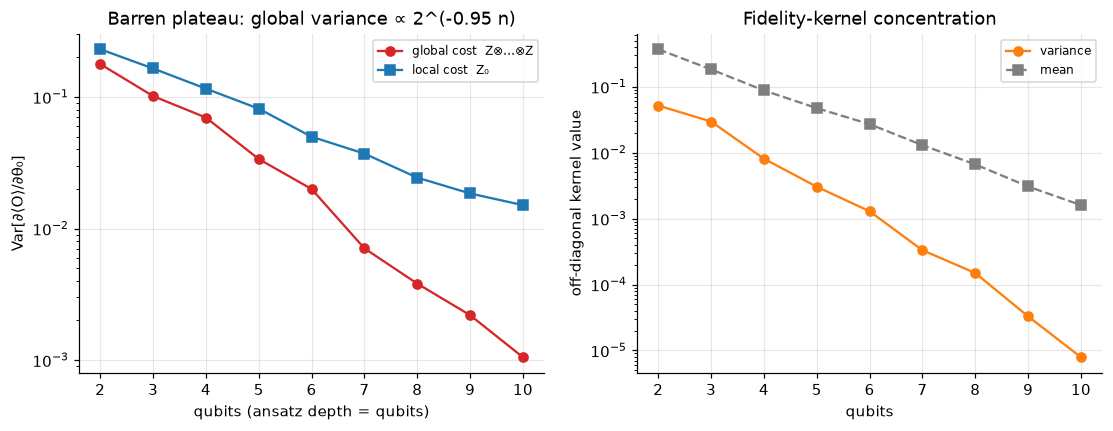

,qubits,global,local,mean,variance
0,2,0.177932,0.230654,0.369986,0.051778
1,3,0.101595,0.164726,0.182945,0.029646
2,4,0.069743,0.115739,0.087753,0.008085
3,5,0.033746,0.081443,0.047361,0.003041
4,6,0.019958,0.049840,0.027028,0.001290
5,7,0.007065,0.037099,0.012985,0.000332
6,8,0.003812,0.024368,0.006629,0.000149
7,9,0.002194,0.018468,0.003066,0.000033
8,10,0.001050,0.015058,0.001600,0.000008


In [12]:
qubits = list(range(2, 11))
bp = pd.DataFrame({
    "qubits": qubits,
    "global": [gradient_variance(n, cost="global", samples=200, seed=1) for n in qubits],
    "local": [gradient_variance(n, cost="local", samples=200, seed=1) for n in qubits],
})
kc = pd.DataFrame([(n, *kernel_concentration(n, num_points=40, seed=1)) for n in qubits],
                  columns=["qubits", "mean", "variance"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(bp.qubits, bp["global"], "o-", color="#d62728", label="global cost  Z⊗…⊗Z")
axes[0].semilogy(bp.qubits, bp["local"], "s-", color="#1f77b4", label="local cost  Z₀")
slope = np.polyfit(bp.qubits, np.log2(bp["global"]), 1)[0]
axes[0].set(xlabel="qubits (ansatz depth = qubits)", ylabel="Var[∂⟨O⟩/∂θ₀]",
            title=f"Barren plateau: global variance ∝ 2^({slope:.2f} n)")
axes[0].legend(fontsize=8)
axes[1].semilogy(kc.qubits, kc["variance"], "o-", color="#ff7f0e", label="variance")
axes[1].semilogy(kc.qubits, kc["mean"], "s--", color="#7f7f7f", label="mean")
axes[1].set(xlabel="qubits", ylabel="off-diagonal kernel value", title="Fidelity-kernel concentration")
axes[1].legend(fontsize=8)
fig.savefig(FIG / "fig5_scaling.png")
plt.show()
bp.merge(kc, on="qubits").round(6)

## Takeaways

* **Classical models win on every dataset.** After symmetric tuning, the best classical model reaches 0.93 to 0.99 test accuracy. The quantum kernel SVC is the stronger quantum model, 0.03 to 0.08 behind on average; it ties or beats the best classical model on only 4 of 15 splits. The VQC is 0.18 to 0.29 behind and never matches it.
* **Tuning matters far more for the quantum models.** Classical accuracy moves by at most ±0.03 with tuning, while the quantum models gain 0.08 to 0.19. Almost all of that comes from one choice: cross-validation picked `[0, 1]` feature scaling over `[0, π]` in every split for both quantum models. With wider angles the fidelity kernel concentrates and the encoded points become hard to separate. An untuned comparison would have overstated the gap.
* **Simulated quantum models are slow.** The quantum models take 1 to 3 orders of magnitude longer to train, though this measures classical simulation and says nothing about real hardware.
* **Noise is not the bottleneck at this scale.** For the shallow circuits used here, VQC accuracy on moons is flat, within the error bars, for CX depolarizing rates up to 10%. The apparent edge from training on the noisy simulator is smaller than the seed-to-seed spread with 3 seeds, so it should not be read as a real effect. The VQC is already limited by shot noise, the COBYLA budget and expressivity.
* **Scaling makes it worse, not better.** The global-cost gradient variance falls roughly exponentially with qubit count (a barren plateau), and the off-diagonal kernel values concentrate towards zero. Both make the larger versions needed for any real advantage harder to train, unless the cost, encoding or bandwidth is designed around them.

These are tiny, low-dimensional problems where classical methods are close to ceiling, so this shows no quantum advantage and was never expected to. What it does show is how easily unequal tuning can distort a comparison, and which effects (encoding scale, concentration, trainability) dominate in practice.